<a href="https://colab.research.google.com/github/mkchoong88/personal-project/blob/main/Supply_Chain_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **AtliQ Mart – Supply Chain Performance Analysis**


<details open>
<summary><h4>📖 Click to expand/collapse Project Background & Problem Statement</h4></summary>

# **Project Background**

### **Executive Summary**
**AtliQ Mart** is a growing Fast-Moving Consumer Goods (FMCG) manufacturer headquartered in Gujarat, India, currently operating across **Surat, Ahmedabad, and Vadodara**. While the company aims to expand into other metros and Tier 1 cities over the next two years, operational bottlenecks are threatening its existing foundation.


### **Problem Statement**
A few key enterprise customers have recently **refused to renew their annual contracts** due to ongoing service delivery issues. Initial investigations suggest a chronic failure in service levels: essential products are either **not arriving on time** or **not being delivered in full**. To protect customer retention and stabilize operations before scaling nationwide, management requires immediate, data-driven visibility into daily supply chain performance.


### **Objective & Analytical Approach**
The Supply Chain Analytics team has been tasked with tracking and diagnosing daily service levels across all customer orders. This notebook implements industry-standard supply chain metrics evaluated against customer-specific target benchmarks:

* **On-Time Delivery (OT) %:** Measures the percentage of orders delivered strictly by the agreed deadline.
* **In-Full Delivery (IF) %:** Measures the percentage of orders delivered with the exact requested quantities.
* **On-Time In-Full (OTIF) %:** Measures perfect deliveries that are both on time and in full.


### **Goal**
To build a reproducible data pipeline and analytical framework that isolates delivery bottlenecks, identifies underperforming customers/cities, and provides leadership with actionable, daily insights to restore service excellence.

> This notebook performs a **complete data analysis cycle**: data loading → exploration → validation → metric calculation → visualization → insights.

[Data Source](https://frontend.codebasics.io/challenges/codebasics-resume-project-challenge/5)

</details>


## Import Python Libraries

In [1]:
# Install packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.2f}'.format)

## Data Loading

In [2]:
# Upload dataset
from google.colab import files
uploaded = files.upload()
DATA_PATH = ''

def load(filename):
    return pd.read_csv(DATA_PATH + filename)

dim_customers       = load('dim_customers.csv')
dim_products        = load('dim_products.csv')
dim_date            = load('dim_date.csv')
dim_targets         = load('dim_targets_orders.csv')
fact_lines          = load('fact_order_lines.csv')
fact_aggregate      = load('fact_orders_aggregate.csv')


Saving dim_customers.csv to dim_customers.csv
Saving dim_date.csv to dim_date.csv
Saving dim_products.csv to dim_products.csv
Saving dim_targets_orders.csv to dim_targets_orders.csv
Saving fact_order_lines.csv to fact_order_lines.csv
Saving fact_orders_aggregate.csv to fact_orders_aggregate.csv


## Data Exploration

In [3]:
# Explore data at every table
tables = {
    'dim_customers':  dim_customers,
    'dim_products':   dim_products,
    'dim_date':       dim_date,
    'dim_targets':    dim_targets,
    'fact_lines':     fact_lines,
    'fact_aggregate': fact_aggregate,
}

for name, df in tables.items():
    print('=' * 100)
    print(f'\t{name}')
    print('=' * 100)
    display(df.head(5))
    print()

	dim_customers


,customer_id,customer_name,city
0,789201,Rel Fresh,Surat
1,789202,Rel Fresh,Ahmedabad
2,789203,Rel Fresh,Vadodara
3,789301,Expression Stores,Surat
4,789303,Expression Stores,Vadodara



	dim_products


,product_name,product_id,category
0,AM Milk 500,25891101,Dairy
1,AM Milk 250,25891102,Dairy
2,AM Milk 100,25891103,Dairy
3,AM Butter 100,25891201,Dairy
4,AM Butter 250,25891202,Dairy



	dim_date


...

,customer_id,ontime_target%,infull_target%,otif_target%
0,789201,87,81,70
1,789202,85,81,69
2,789203,92,76,70
3,789301,89,78,69
4,789303,88,78,69



	fact_lines


,order_id,order_placement_date,customer_id,product_id,order_qty,agreed_delivery_date,actual_delivery_date,delivery_qty,In Full,On Time,On Time In Full
0,FMR34203601,"Tuesday, March 1, 2022",789203,25891601,110,"Friday, March 4, 2022","Friday, March 4, 2022",110,1,1,1
1,FMR32320302,"Tuesday, March 1, 2022",789320,25891203,347,"Wednesday, March 2, 2022","Wednesday, March 2, 2022",347,1,1,1
2,FMR33320501,"Tuesday, March 1, 2022",789320,25891203,187,"Thursday, March 3, 2022","Thursday, March 3, 2022",150,0,1,0
3,FMR34220601,"Tuesday, March 1, 2022",789220,25891203,235,"Friday, March 4, 2022","Friday, March 4, 2022",235,1,1,1
4,FMR33703603,"Tuesday, March 1, 2022",789703,25891203,176,"Thursday, March 3, 2022","Thursday, March 3, 2022",176,1,1,1



	fact_aggregate


,order_id,customer_id,order_placement_date,on_time,in_full,otif
0,FMR32103503,789103,01-Mar-22,1,0,0
1,FMR34103403,789103,01-Mar-22,1,0,0
2,FMR32103602,789103,01-Mar-22,1,0,0
3,FMR33103602,789103,01-Mar-22,1,0,0
4,FMR33103401,789103,01-Mar-22,1,0,0


In [4]:
# Schema for each table
for name, df in tables.items():
    print('=' * 100)
    print(f'\t{name}')
    print('=' * 100)
    print(df.info())
    print()

	dim_customers
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35 entries, 0 to 34
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customer_id    35 non-null     int64 
 1   customer_name  35 non-null     object
 2   city           35 non-null     object
dtypes: int64(1), object(2)
memory usage: 972.0+ bytes
None

	dim_products
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   product_name  18 non-null     object
 1   product_id    18 non-null     int64 
 2   category      18 non-null     object
dtypes: int64(1), object(2)
memory usage: 564.0+ bytes
None

	dim_date
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 183 entries, 0 to 182
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   date     183 non-null    ob

In [5]:
# Descriptive statistics for fact tables
for name, df in tables.items():
    if name.startswith('fact_'):
        print('=' * 100)
        print(f'\t{name}')
        print('=' * 100)
        display(df.describe())
        print()

	fact_lines


,customer_id,product_id,order_qty,delivery_qty,In Full,On Time,On Time In Full
count,57096.00,57096.00,57096.00,57096.00,57096.00,57096.00,57096.00
mean,789427.22,25891351.66,235.16,227.15,0.66,0.71,0.48
std,224.25,170.70,141.00,137.11,0.47,0.45,0.50
min,789101.00,25891101.00,20.00,16.00,0.00,0.00,0.00
25%,789220.00,25891202.00,111.00,106.00,0.00,0.00,0.00
50%,789420.00,25891303.00,207.00,200.00,1.00,1.00,0.00
75%,789603.00,25891502.00,361.00,347.00,1.00,1.00,1.00
max,789903.00,25891603.00,500.00,500.00,1.00,1.00,1.00



	fact_aggregate


,customer_id,on_time,in_full,otif
count,31729.00,31729.00,31729.00,31729.00
mean,789423.56,0.59,0.53,0.29
std,219.10,0.49,0.50,0.45
min,789101.00,0.00,0.00,0.00
25%,789220.00,0.00,0.00,0.00
50%,789420.00,1.00,1.00,0.00
75%,789601.00,1.00,1.00,1.00
max,789903.00,1.00,1.00,1.00


## Data Cleaning & Validation

In [6]:
# Rename and remove whitespaces in column names and in data
for name, df in tables.items():
    df.columns = (
        df.columns
        .str.strip()
        .str.lower()
        .str.replace("%", "")
        .str.replace(" ", "_")
    )
    print(f'{name}:')
    print(df.columns.to_list())
    print()

    for col in df.columns:
      if df[col].dtype == 'object':
        df[col] = df[col].str.strip()

dim_customers:
['customer_id', 'customer_name', 'city']

dim_products:
['product_name', 'product_id', 'category']

dim_date:
['date', 'mmm_yy', 'week_no']

dim_targets:
['customer_id', 'ontime_target', 'infull_target', 'otif_target']

fact_lines:
['order_id', 'order_placement_date', 'customer_id', 'product_id', 'order_qty', 'agreed_delivery_date', 'actual_delivery_date', 'delivery_qty', 'in_full', 'on_time', 'on_time_in_full']

fact_aggregate:
['order_id', 'customer_id', 'order_placement_date', 'on_time', 'in_full', 'otif']



In [7]:
# Missing values
for name, df in tables.items():
    missing = df.isnull().sum()
    if missing.any():
        print(f'{name}:')
        print(missing[missing > 0].to_string())
    else:
        print(f'{name}: No missing values')

dim_customers: No missing values
dim_products: No missing values
dim_date: No missing values
dim_targets: No missing values
fact_lines: No missing values
fact_aggregate: No missing values


In [8]:
# Duplicate rows
for name, df in tables.items():
    dup = df.duplicated().sum()
    print(f'{name}: {dup} duplicates')

dim_customers: 0 duplicates
dim_products: 0 duplicates
dim_date: 0 duplicates
dim_targets: 0 duplicates
fact_lines: 0 duplicates
fact_aggregate: 0 duplicates


In [9]:
# Change date columns to datetime
# fact_order_lines uses 'Weekday, Month DD, YYYY' format
date_cols = ['order_placement_date', 'agreed_delivery_date', 'actual_delivery_date']
for col in date_cols:
    fact_lines[col] = pd.to_datetime(fact_lines[col], format='mixed', dayfirst=False)

# fact_orders_aggregate uses DD-Mon-YY format
fact_aggregate['order_placement_date'] = pd.to_datetime(
    fact_aggregate['order_placement_date'], format='%d-%b-%y')

# dim_date
dim_date['date']   = pd.to_datetime(dim_date['date'],   format='%d-%b-%y')
dim_date['mmm_yy'] = pd.to_datetime(dim_date['mmm_yy'], format='%d-%b-%y')

print('fact_order_lines date range:',
      fact_lines['order_placement_date'].min().date(),
      '→',
      fact_lines['order_placement_date'].max().date())

fact_order_lines date range: 2022-03-01 → 2022-08-30


In [10]:
# Referential integrity check
customers_in_dim_targets = set(dim_targets['customer_id'])
customers_in_dim_customers = set(dim_customers['customer_id'])
customers_in_fact_lines = set(fact_lines['customer_id'])
customers_in_fact_agg = set(fact_aggregate['customer_id'])

print('Customers in dim_customers  :', len(customers_in_dim_customers))
print('Customers in dim_targets    :', len(customers_in_dim_targets))
print('Customers in fact_lines     :', len(customers_in_fact_lines))
print('Customers in fact_aggregate :', len(customers_in_fact_agg))

unmapped_customers = customers_in_fact_lines - customers_in_dim_customers
print('\nUnmapped customer IDs in fact_lines:', unmapped_customers if unmapped_customers else 'None')

products_in_dim_products  = set(dim_products['product_id'])
products_in_fact_lines = set(fact_lines['product_id'])
unmapped_products = products_in_fact_lines - products_in_dim_products
print('Unmapped product IDs in fact_lines:', unmapped_products if unmapped_products else 'None')

Customers in dim_customers  : 35
Customers in dim_targets    : 35
Customers in fact_lines     : 35
Customers in fact_aggregate : 35

Unmapped customer IDs in fact_lines: None
Unmapped product IDs in fact_lines: None


In [11]:
# Business logic validation
# Over-delivery: delivered_qty should not exceed order_qty
overdelivered = fact_lines[fact_lines['delivery_qty'] > fact_lines['order_qty']]
print(f'Over delivered items: {len(overdelivered)}')

# In-Full flag should align: delivery_qty >= order_qty <=> In Full = 1
computed_infull  = (
    fact_lines['delivery_qty'] >= fact_lines['order_qty']
).astype(int)
if_mismatch    = (computed_infull != fact_lines['in_full']).sum()
print(f'In Full mismatches: {if_mismatch}')

# On-Time check: actual <= agreed <=> On Time = 1
computed_ontime = (
    fact_lines['actual_delivery_date'] <= fact_lines['agreed_delivery_date']
).astype(int)
ot_mismatch     = (computed_ontime != fact_lines['on_time']).sum()
print(f'On Time mismatches: {ot_mismatch}')

Over delivered items: 0
In Full mismatches: 0
On Time mismatches: 0


## Feature Engineering

In [12]:
# Add date dimensions to dim_date
dim_date['year'] = dim_date['date'].dt.year
dim_date['quarter'] = dim_date['date'].dt.quarter
dim_date['month_num'] = dim_date['date'].dt.month
dim_date['month_year'] = dim_date['date'].dt.to_period('M').dt.to_timestamp()
dim_date['month_label'] = dim_date['date'].dt.strftime('%b-%y')
dim_date['week_of_year'] = dim_date['date'].dt.isocalendar().week
dim_date['day_of_week'] = dim_date['date'].dt.day_name()
dim_date['is_weekend'] = dim_date['date'].dt.dayofweek.isin([5, 6])

dim_date = dim_date.drop(columns=['mmm_yy', 'week_no'], errors='ignore')

display(dim_date.head(5))

missing_date = dim_date.isna().sum()
if missing_date.any():
    print('\ndim_date missing values:')
    print(missing_date[missing_date > 0].to_string())
else:
    print('\ndim_date: No missing values')


,date,year,quarter,month_num,month_year,month_label,week_of_year,day_of_week,is_weekend
0,2022-04-01,2022,2,4,2022-04-01,Apr-22,13,Friday,False
1,2022-04-03,2022,2,4,2022-04-01,Apr-22,13,Sunday,True
2,2022-04-04,2022,2,4,2022-04-01,Apr-22,14,Monday,False
3,2022-04-05,2022,2,4,2022-04-01,Apr-22,14,Tuesday,False
4,2022-04-06,2022,2,4,2022-04-01,Apr-22,14,Wednesday,False



dim_date: No missing values


In [13]:
# Merge fact_lines with dimensions
fact_lines = (
    fact_lines
    .merge(dim_customers, on='customer_id', how='left')
    .merge(dim_products, on='product_id', how='left')
    .merge(dim_date, left_on='order_placement_date', right_on='date', how='left')
)

# Delivery delay in days
fact_lines['delivery_delay_days'] = (
    fact_lines['actual_delivery_date'] - fact_lines['agreed_delivery_date']
).dt.days

# Merge fact_aggregate with dimensions
fact_aggregate = (
    fact_aggregate
    .merge(dim_customers, on='customer_id', how='left')
    .merge(dim_targets, on='customer_id', how='left')
    .merge(dim_date, left_on='order_placement_date', right_on='date', how='left')
)

print('Quick check if merging properly')
print('fact_lines columns  :', list(fact_lines.columns))
print('fact_aggregate columns :', list(fact_aggregate.columns))

Quick check if merging properly
fact_lines columns  : ['order_id', 'order_placement_date', 'customer_id', 'product_id', 'order_qty', 'agreed_delivery_date', 'actual_delivery_date', 'delivery_qty', 'in_full', 'on_time', 'on_time_in_full', 'customer_name', 'city', 'product_name', 'category', 'date', 'year', 'quarter', 'month_num', 'month_year', 'month_label', 'week_of_year', 'day_of_week', 'is_weekend', 'delivery_delay_days']
fact_aggregate columns : ['order_id', 'customer_id', 'order_placement_date', 'on_time', 'in_full', 'otif', 'customer_name', 'city', 'ontime_target', 'infull_target', 'otif_target', 'date', 'year', 'quarter', 'month_num', 'month_year', 'month_label', 'week_of_year', 'day_of_week', 'is_weekend']


## Core KPI Metrics

| KPI | Formula | Table |
|-----|---------|-------|
| Total Order Lines | COUNT(*) | fact_order_lines |
| LIFR% | Lines_In_Full / Total_Lines × 100 | fact_order_lines |
| VOFR% | Total_Qty_Delivered / Total_Qty_Ordered × 100 | fact_order_lines |
| OT% | Orders_On_Time / Total_Orders × 100 | fact_orders_aggregate |
| IF% | Orders_In_Full / Total_Orders × 100 | fact_orders_aggregate |
| OTIF% | Orders_OTIF / Total_Orders × 100 | fact_orders_aggregate |

In [14]:
# Line-level metrics
total_lines      = len(fact_lines)
lines_in_full    = fact_lines['in_full'].sum()
LIFR             = lines_in_full / total_lines * 100

total_qty_ordered   = fact_lines['order_qty'].sum()
total_qty_delivered = fact_lines['delivery_qty'].sum()
VOFR = total_qty_delivered / total_qty_ordered * 100

# Order-level metrics
total_orders  = len(fact_aggregate)
orders_ot     = fact_aggregate['on_time'].sum()
orders_if     = fact_aggregate['in_full'].sum()
orders_otif   = fact_aggregate['otif'].sum()
OT_pct        = orders_ot   / total_orders * 100
IF_pct        = orders_if   / total_orders * 100
OTIF_pct      = orders_otif / total_orders * 100

# Weighted average targets (customers with more orders carry more weights)
avg_ot_target = fact_aggregate['ontime_target'].mean()
avg_if_target = fact_aggregate['infull_target'].mean()
avg_otif_target = fact_aggregate['otif_target'].mean()

# Top level summary
print('=' * 100)
print('\tOVERALL SUPPLY CHAIN KPI SUMMARY')
print('=' * 100)
print(f'  Total Order Lines         : {total_lines:>12,}')
print(f'  Total Orders              : {total_orders:>12,}')
print(f'  Total Qty Ordered         : {total_qty_ordered:>12,}')
print(f'  Total Qty Delivered       : {total_qty_delivered:>12,}')
print()
print(f'  Line Fill Rate (LIFR)     : {LIFR:>11.2f}%')
print(f'  Volume Fill Rate (VOFR)   : {VOFR:>11.2f}%')
print()
print(f'  On-Time %  (OT)           : {OT_pct:>11.2f}%  │ Avg Target: {avg_ot_target:.2f}%')
print(f'  In-Full %  (IF)           : {IF_pct:>11.2f}%  │ Avg Target: {avg_if_target:.2f}%')
print(f'  On-Time & In-Full % (OTIF): {OTIF_pct:>11.2f}%  │ Avg Target: {avg_otif_target:.2f}%')
print()
print(f'  Gap OT   (Actual - Target): {OT_pct - avg_ot_target:>+11.2f}%')
print(f'  Gap IF   (Actual - Target): {IF_pct - avg_if_target:>+11.2f}%')
print(f'  Gap OTIF (Actual - Target): {OTIF_pct - avg_otif_target:>+11.2f}%')

	OVERALL SUPPLY CHAIN KPI SUMMARY
  Total Order Lines         :       57,096
  Total Orders              :       31,729
  Total Qty Ordered         :   13,426,936
  Total Qty Delivered       :   12,969,157

  Line Fill Rate (LIFR)     :       65.96%
  Volume Fill Rate (VOFR)   :       96.59%

  On-Time %  (OT)           :       59.03%  │ Avg Target: 85.24%
  In-Full %  (IF)           :       52.78%  │ Avg Target: 76.31%
  On-Time & In-Full % (OTIF):       29.02%  │ Avg Target: 65.10%

  Gap OT   (Actual - Target):      -26.21%
  Gap IF   (Actual - Target):      -23.53%
  Gap OTIF (Actual - Target):      -36.08%


## KPI Overall Performance

In [15]:
# Color palette

# Color for indicator
COLOR_GREEN   = '#2ecc71'
COLOR_RED     = '#e74c3c'
COLOR_ORANGE  = '#e67e22'

# Color for category
COLOR_BLUE    = '#3498db'
COLOR_PURPLE  = '#9b59b6'
COLOR_TEAL    = '#1abc9c'

In [16]:
# KPI gauge cards
fig = make_subplots(
    rows=2, cols=3,
    subplot_titles=('LIFR%', 'VOFR%', 'OT%', 'IF%', 'OTIF%'),
    specs=[
        [{'type': 'indicator'}, {'type': 'indicator'}, None],
        [{'type': 'indicator'}, {'type': 'indicator'}, {'type': 'indicator'}]
    ],
    vertical_spacing=0.15
)

kpis = [
    # Format: (title, value, target, row, col)
    ('LIFR%',  LIFR,     None,             1, 1),
    ('VOFR%',  VOFR,     None,             1, 2),
    ('OT%',    OT_pct,   avg_ot_target,    2, 1),
    ('IF%',    IF_pct,   avg_if_target,    2, 2),
    ('OTIF%',  OTIF_pct, avg_otif_target,  2, 3),
]

for title, value, target, row, col in kpis:
    delta = dict(reference=target, valueformat='.1f') if target else None
    fig.add_trace(
        go.Indicator(
            mode='gauge+number+delta' if target else 'gauge+number',
            value=value,
            number={'suffix': '%', 'font': {'size': 26}},
            delta=delta,

            gauge=dict(
                axis={'range': [0, 100]},
                bar={'color': COLOR_BLUE},
                steps=[
                    {'range': [0, 50], 'color': '#f8d7da'},
                    {'range': [50,75], 'color': '#fff3cd'},
                    {'range': [75, 100],'color': '#d4edda'},
                ],
                threshold=dict(
                    line={'color': 'red', 'width': 3},
                    thickness=0.75,
                    value=target or value
                )
            )
        ),
        row=row, col=col
    )

fig.update_layout(
    title=dict(
        text='<b>Supply Chain KPI – Overall Performance</b>',
        font={'size': 20},
        x=0.5
        ),
    height=550,
    template='plotly_white'
)
fig.update_annotations(font=dict(size=13))

fig.show()

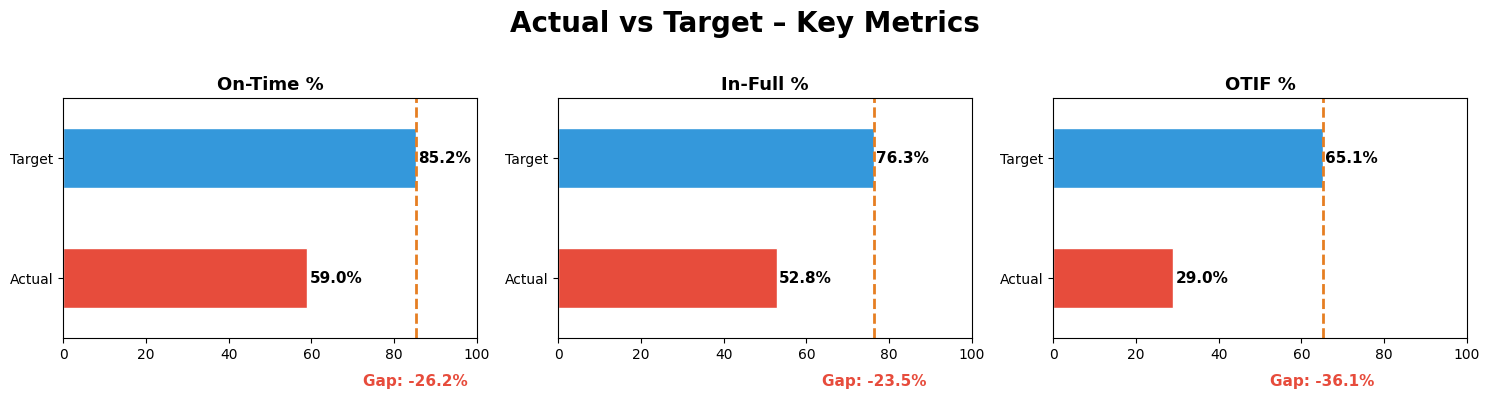

In [17]:
# Actual vs Target – Bullet Chart
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics = [
    ('On-Time %',  OT_pct,   avg_ot_target),
    ('In-Full %',  IF_pct,   avg_if_target),
    ('OTIF %',     OTIF_pct, avg_otif_target),
]

for ax, (title, actual, target) in zip(axes, metrics):
    color  = COLOR_GREEN if actual >= target else COLOR_RED

    ax.barh(['Actual', 'Target'], [actual, target],
            color=[color, COLOR_BLUE], edgecolor='white', height=0.5)

    ax.set_xlim(0, 100)
    ax.set_ylim(-0.5, 1.5)
    ax.axvline(target, color=COLOR_ORANGE, linewidth=2, linestyle='--', label='Target')

    ax.set_title(title, fontsize=13, fontweight='bold')

    for i, v in enumerate([actual, target]):
        ax.text(v + 0.5, i, f'{v:.1f}%', va='center', fontsize=11, fontweight='bold')
    gap = actual - target
    ax.text(target/100, -0.20, f'Gap: {gap:+.1f}%',
            transform=ax.transAxes, ha='center', fontsize=11,
            color=COLOR_GREEN if gap >= 0 else COLOR_RED, fontweight='bold')

fig.suptitle(
    'Actual vs Target – Key Metrics',
    fontsize=20, fontweight='bold', y=1.02
)
plt.tight_layout()
plt.show()

## Time-Series Analysis – Monthly Trends

In [18]:
# Monthly KPI trends (order-level)
monthly_kpis = (
    fact_aggregate
    .groupby('month_year')
    .agg(
        total_orders  = ('order_id', 'count'),
        ot_orders     = ('on_time', 'sum'),
        if_orders     = ('in_full', 'sum'),
        otif_orders   = ('otif', 'sum'),
        avg_ot_tgt    = ('ontime_target', 'mean'),
        avg_if_tgt    = ('infull_target', 'mean'),
        avg_otif_tgt  = ('otif_target', 'mean'),
    )
    .reset_index()
)

monthly_kpis['OT_pct']   = monthly_kpis['ot_orders']   / monthly_kpis['total_orders'] * 100
monthly_kpis['IF_pct']   = monthly_kpis['if_orders']   / monthly_kpis['total_orders'] * 100
monthly_kpis['OTIF_pct'] = monthly_kpis['otif_orders'] / monthly_kpis['total_orders'] * 100

display(monthly_kpis[['month_year','total_orders','OT_pct',
                      'IF_pct','OTIF_pct','avg_ot_tgt',
                      'avg_if_tgt','avg_otif_tgt']])

,month_year,total_orders,OT_pct,IF_pct,OTIF_pct,avg_ot_tgt,avg_if_tgt,avg_otif_tgt
0,2022-03-01,5407,59.57,52.34,28.87,85.26,76.34,65.14
1,2022-04-01,5253,59.32,52.56,28.67,85.24,76.31,65.10
2,2022-05-01,5417,58.50,53.66,29.13,85.27,76.31,65.12
3,2022-06-01,5213,58.51,52.04,28.72,85.18,76.30,65.04
4,2022-07-01,5339,59.39,52.48,29.35,85.25,76.31,65.11
5,2022-08-01,5100,58.88,53.61,29.39,85.25,76.30,65.09


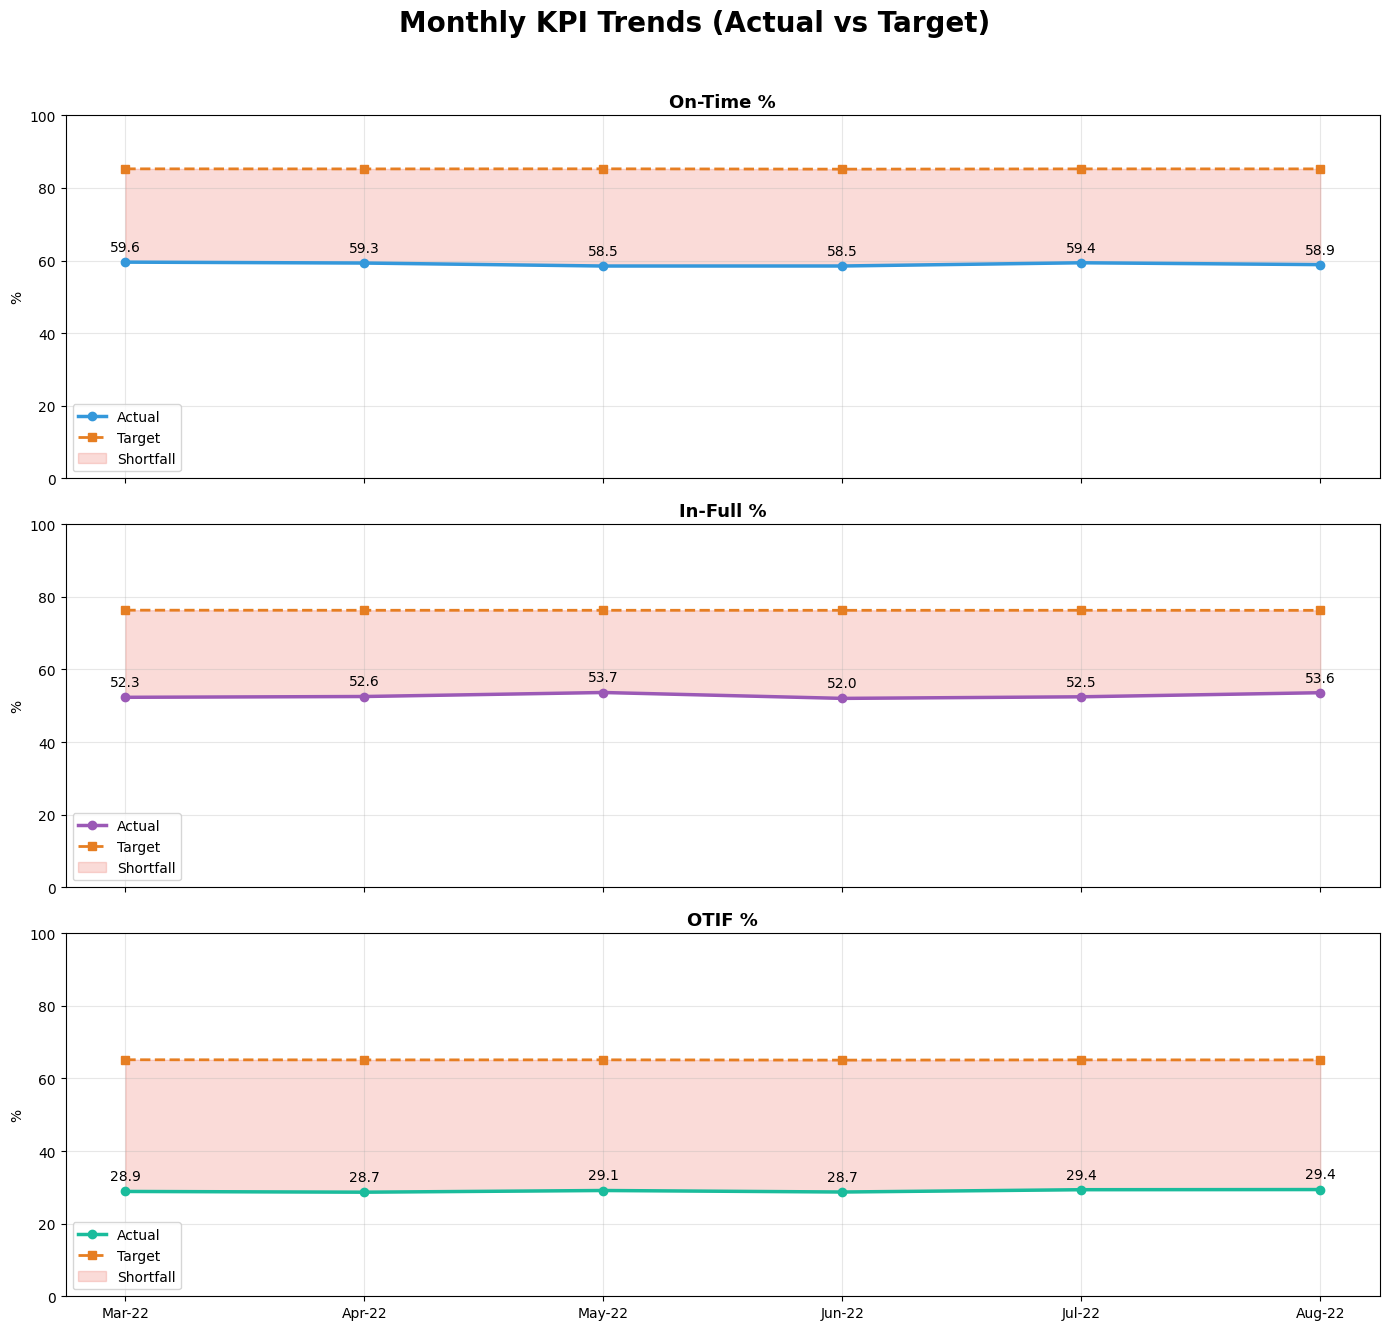

In [19]:
# Monthly trend lines
fig, axes = plt.subplots(3, 1, figsize=(14, 13), sharex=True)

triplets = [
    # Format: (value, target, title, color)
    ('OT_pct',   'avg_ot_tgt',   'On-Time %',   COLOR_BLUE),
    ('IF_pct',   'avg_if_tgt',   'In-Full %',   COLOR_PURPLE),
    ('OTIF_pct', 'avg_otif_tgt', 'OTIF %',      COLOR_TEAL),
]

x = monthly_kpis['month_year'].dt.strftime('%b-%y')

for ax, (value, target, title, color) in zip(axes, triplets):
    ax.plot(x, monthly_kpis[value], marker='o', color=color,
            linewidth=2.5, label='Actual')
    ax.plot(x, monthly_kpis[target], marker='s', color=COLOR_ORANGE,
            linewidth=2, linestyle='--', label='Target')

    ax.fill_between(x, monthly_kpis[value], monthly_kpis[target],
                    where=(monthly_kpis[value] < monthly_kpis[target]),
                    alpha=0.2, color=COLOR_RED, label='Shortfall')

    ax.set_ylabel('%')
    ax.set_ylim(0, 100)
    ax.set_title(title, fontsize=13, fontweight='bold')

    ax.legend(loc='lower left')
    ax.grid(alpha=0.3)
    for xi, value in enumerate(monthly_kpis[value]):
        ax.annotate(f'{value:.1f}', (xi, value), textcoords='offset points',
                    xytext=(0, 8), ha='center', fontsize=10)

fig.suptitle(
    'Monthly KPI Trends (Actual vs Target)',
    fontsize=20, fontweight='bold', y=1.02
)
plt.tight_layout()
plt.show()

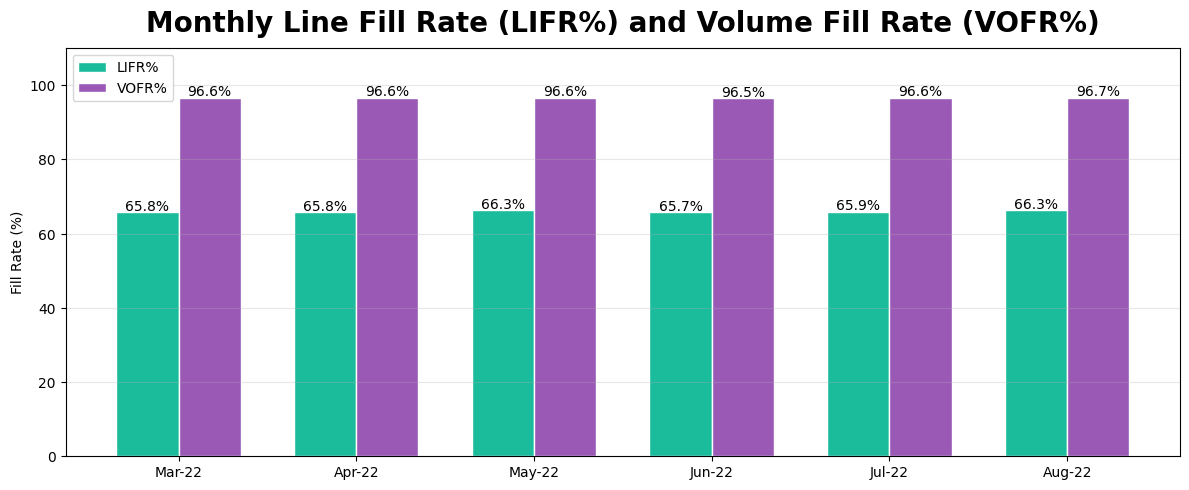

In [20]:
# Monthly LIFR and VOFR
monthly_lines = (
    fact_lines
    .groupby('month_year')
    .agg(
        total_lines   = ('order_id', 'count'),
        lines_in_full = ('in_full', 'sum'),
        qty_ordered   = ('order_qty', 'sum'),
        qty_delivered = ('delivery_qty', 'sum'),
    )
    .reset_index()
)

monthly_lines['LIFR_pct'] = monthly_lines['lines_in_full'] / monthly_lines['total_lines'] * 100
monthly_lines['VOFR_pct'] = monthly_lines['qty_delivered'] / monthly_lines['qty_ordered'] * 100

fig, ax = plt.subplots(figsize=(12, 5))
x  = np.arange(len(monthly_lines))
w  = 0.35

ax.bar(x - w/2, monthly_lines['LIFR_pct'], width=w, color=COLOR_TEAL,
       label='LIFR%', edgecolor='white')
ax.bar(x + w/2, monthly_lines['VOFR_pct'], width=w, color=COLOR_PURPLE,
       label='VOFR%', edgecolor='white')

ax.set_xticks(x)
ax.set_xticklabels(monthly_lines['month_year'].dt.strftime('%b-%y'))

ax.set_ylim(0, 110)
ax.set_ylabel('Fill Rate (%)')
ax.set_title('Monthly Line Fill Rate (LIFR%) and Volume Fill Rate (VOFR%)',
             fontsize=20, fontweight='bold', y=1.02)

ax.legend(loc='upper left')
ax.grid(axis='y', alpha=0.3)
for xi, (l, v) in enumerate(zip(monthly_lines['LIFR_pct'], monthly_lines['VOFR_pct'])):
    ax.text(xi - w/2, l + 0.5, f'{l:.1f}%', ha='center', fontsize=10)
    ax.text(xi + w/2, v + 0.5, f'{v:.1f}%', ha='center', fontsize=10)

plt.tight_layout()
plt.show()

## Customer-Level Analysis

In [21]:
# KPI metrics at customer level
customer_kpis = (
    fact_aggregate
    .groupby(['customer_id'])
    .agg(
        customer_name = ('customer_name', 'first'),
        city          = ('city', 'first'),
        total_orders = ('order_id', 'count'),
        ot_orders    = ('on_time', 'sum'),
        if_orders    = ('in_full', 'sum'),
        otif_orders  = ('otif', 'sum'),
        ot_target    = ('ontime_target', 'first'),
        if_target    = ('infull_target', 'first'),
        otif_target  = ('otif_target', 'first'),
    )
    .reset_index()
)

customer_kpis['OT_pct']   = customer_kpis['ot_orders']   / customer_kpis['total_orders'] * 100
customer_kpis['IF_pct']   = customer_kpis['if_orders']   / customer_kpis['total_orders'] * 100
customer_kpis['OTIF_pct'] = customer_kpis['otif_orders'] / customer_kpis['total_orders'] * 100

customer_kpis['OT_gap']   = customer_kpis['OT_pct']   - customer_kpis['ot_target']
customer_kpis['IF_gap']   = customer_kpis['IF_pct']   - customer_kpis['if_target']
customer_kpis['OTIF_gap'] = customer_kpis['OTIF_pct'] - customer_kpis['otif_target']

customer_kpis = customer_kpis.sort_values('OTIF_pct', ascending=False)

display(customer_kpis[['customer_name','city','total_orders',
                         'OT_pct','ot_target','OT_gap',
                         'IF_pct','if_target','IF_gap',
                         'OTIF_pct','otif_target','OTIF_gap']].round(2))

,customer_name,city,total_orders,OT_pct,ot_target,OT_gap,IF_pct,if_target,IF_gap,OTIF_pct,otif_target,OTIF_gap
16,Propel Mart,Vadodara,791,74.08,86,-11.92,61.31,79,-17.69,42.48,68,-25.52
11,Expression Stores,Vadodara,820,70.49,88,-17.51,63.54,78,-14.46,41.59,69,-27.41
26,Info Stores,Vadodara,842,71.14,92,-20.86,62.59,75,-12.41,41.33,69,-27.67
30,Sorefoz Mart,Vadodara,829,73.70,85,-11.30,60.80,78,-17.20,41.13,66,-24.87
15,Propel Mart,Ahmedabad,823,74.00,89,-15.00,59.17,80,-20.83,40.70,71,-30.30
6,Rel Fresh,Ahmedabad,843,73.07,85,-11.93,60.62,81,-20.38,40.33,69,-28.67
28,Expert Mart,Vadodara,837,72.04,90,-17.96,60.45,79,-18.55,39.90,71,-31.10
8,Atlas Stores,Surat,799,72.34,91,-18.66,59.57,76,-16.43,39.80,69,-29.20
14,Propel Mart,Surat,810,72.84,85,-12.16,58.77,79,-20.23,39.63,67,-27.37
32,Logic Stores,Ahmedabad,836,71.17,89,-17.83,60.77,75,-14.23,39.59,67,-27.41


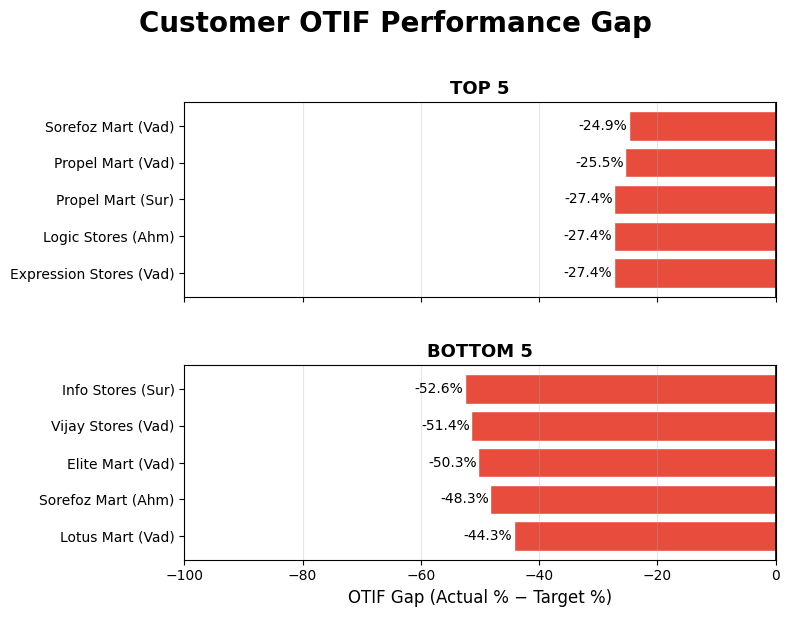

In [22]:
# Customer OTIF% vs Target (Top 5 and Bottom 5)
fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

customer_sorted = customer_kpis.sort_values('OTIF_gap', ascending=False)

customer_top_5 = customer_sorted.head(5).iloc[-1::-1]
customer_bottom_5 = customer_sorted.tail(5)
customer_top_5.name = 'TOP 5'
customer_bottom_5.name = 'BOTTOM 5'

for ax, df in zip(axes, [customer_top_5, customer_bottom_5]):
    colors = [COLOR_GREEN if g >= 0 else COLOR_RED for g in df['OTIF_gap']]

    bars = ax.barh(
        [f"{row['customer_name']} ({row['city'][:3]})" for _, row in df.iterrows()],
        df['OTIF_gap'],
        color=colors, edgecolor='white'
    )

    ax.axvline(0, color='black', linewidth=1.2)
    for bar, val in zip(bars, df['OTIF_gap']):
        ax.text(val + (0.2 if val >= 0 else -0.2), bar.get_y() + bar.get_height()/2,
                f'{val:+.1f}%', va='center',
                ha='left' if val >= 0 else 'right', fontsize=10)

    ax.set_xlim(-100)
    ax.set_title(df.name, fontsize=13, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)

axes[-1].set_xlabel('OTIF Gap (Actual % − Target %)', fontsize=12)

fig.suptitle(
    'Customer OTIF Performance Gap',
    fontsize=20, fontweight='bold', y=1.02
)
plt.tight_layout(h_pad=3.0)
plt.show()

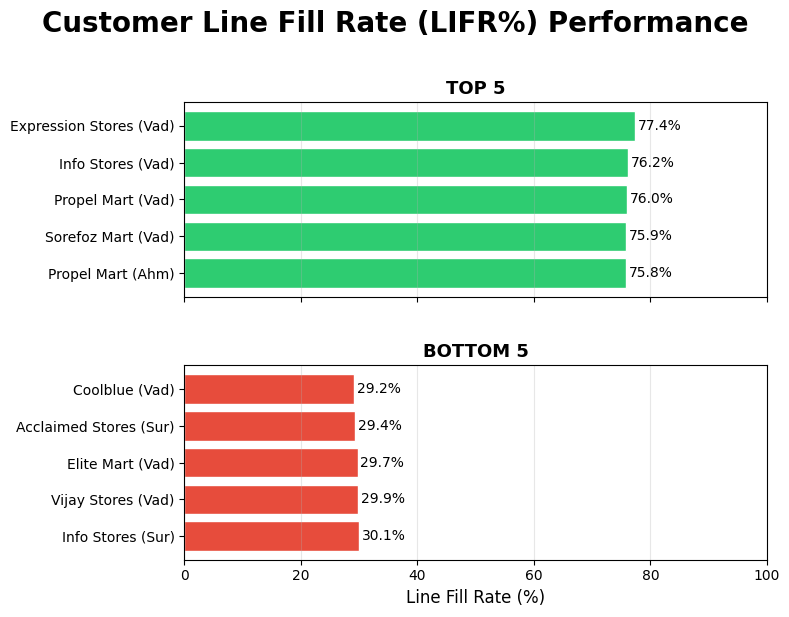

In [23]:
# Customer LIFR% (Top 5 and Bottom 5)
customer_lifr = (
    fact_lines
    .groupby(['customer_name', 'city'])
    .agg(lines_total=('in_full', 'count'), lines_if=('in_full', 'sum'))
    .assign(LIFR=lambda d: d['lines_if'] / d['lines_total'] * 100)
    .sort_values('LIFR', ascending=False)
    .reset_index()
)

fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

customer_lifr_top_5 = customer_lifr.head(5).iloc[-1::-1]
customer_lifr_bottom_5 = customer_lifr.tail(5)

customer_lifr_top_5.name = 'TOP 5'
customer_lifr_bottom_5.name = 'BOTTOM 5'

for ax, df in zip(axes, [customer_lifr_top_5, customer_lifr_bottom_5]):
    colors = [COLOR_GREEN if v >= 65 else COLOR_ORANGE if v >= 50 else COLOR_RED for v in df['LIFR']]

    bars = ax.barh(
        [f"{row['customer_name']} ({row['city'][:3]})" for _, row in df.iterrows()],
        df['LIFR'],
        color=colors, edgecolor='white'
    )

    for bar, val in zip(bars, df['LIFR']):
        ax.text(val + 0.5, bar.get_y() + bar.get_height() / 2,
                f'{val:.1f}%', va='center', ha='left', fontsize=10)

    ax.set_xlim(0, 100)
    ax.set_title(df.name, fontsize=13, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)

axes[-1].set_xlabel('Line Fill Rate (%)', fontsize=12)

fig.suptitle(
    'Customer Line Fill Rate (LIFR%) Performance',
    fontsize=20, fontweight='bold', y=1.02
)
plt.tight_layout(h_pad=3.0)
plt.show()


## Product-Level Analysis

In [24]:
# Product & category LIFR / VOFR
product_kpis = (
    fact_lines
    .groupby(['product_name', 'category'])
    .agg(
        total_lines   = ('in_full', 'count'),
        lines_in_full = ('in_full', 'sum'),
        qty_ordered   = ('order_qty', 'sum'),
        qty_delivered = ('delivery_qty', 'sum'),
        avg_delay     = ('delivery_delay_days', 'mean'),
    )
    .reset_index()
)

product_kpis['LIFR_pct'] = product_kpis['lines_in_full'] / product_kpis['total_lines'] * 100
product_kpis['VOFR_pct'] = product_kpis['qty_delivered'] / product_kpis['qty_ordered'] * 100

product_kpis_sorted = product_kpis.sort_values('LIFR_pct', ascending=False)
display(product_kpis_sorted[['product_name','category','LIFR_pct',
                             'VOFR_pct','avg_delay']].round(2))

,product_name,category,LIFR_pct,VOFR_pct,avg_delay
2,AM Biscuits 750,Food,68.05,96.85,0.40
14,AM Milk 500,Dairy,67.51,96.71,0.42
7,AM Curd 250,Dairy,67.05,96.72,0.41
6,AM Curd 100,Dairy,66.73,96.62,0.43
10,AM Ghee 150,Dairy,66.72,96.69,0.44
3,AM Butter 100,Dairy,66.66,96.59,0.43
17,AM Tea 500,Beverages,66.14,96.52,0.42
1,AM Biscuits 500,Food,66.10,96.49,0.42
13,AM Milk 250,Dairy,65.91,96.61,0.44
9,AM Ghee 100,Dairy,65.75,96.59,0.45


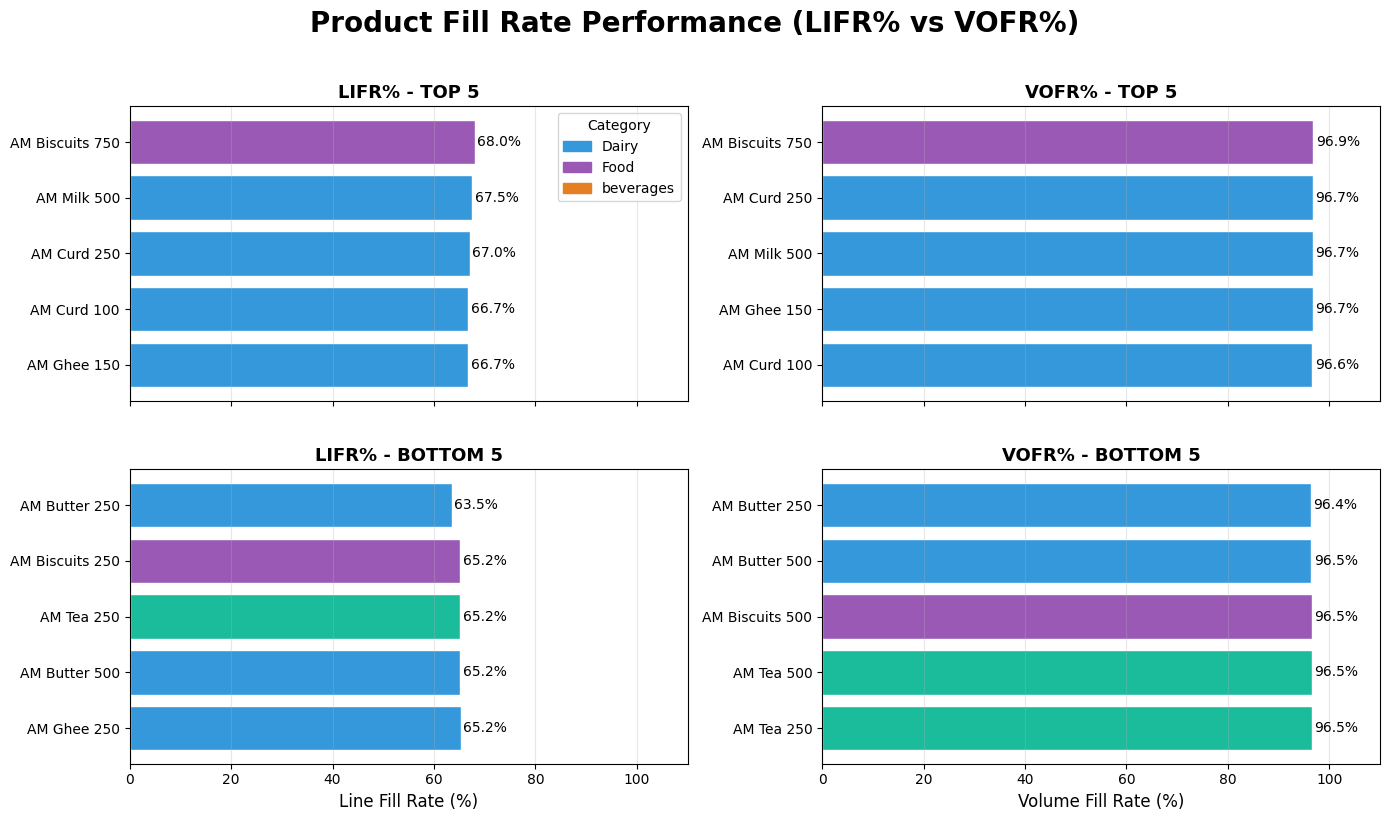

In [25]:
# Product LIFR bar chart
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)

axes_flat = axes.flatten()

product_lifr_top_5 = product_kpis.sort_values('LIFR_pct', ascending=False).head(5).iloc[-1::-1]
product_lifr_bottom_5 = product_kpis.sort_values('LIFR_pct', ascending=False).tail(5)

product_vofr_top_5 = product_kpis.sort_values('VOFR_pct', ascending=False).head(5).iloc[-1::-1]
product_vofr_bottom_5 = product_kpis.sort_values('VOFR_pct', ascending=False).tail(5)

product_lifr_top_5.name = 'LIFR% - TOP 5'
product_lifr_bottom_5.name = 'LIFR% - BOTTOM 5'

product_vofr_top_5.name = 'VOFR% - TOP 5'
product_vofr_bottom_5.name = 'VOFR% - BOTTOM 5'

cat_colors = {'Dairy': COLOR_BLUE, 'Food': COLOR_PURPLE, 'beverages': COLOR_ORANGE}

dfs = [product_lifr_top_5, product_vofr_top_5, product_lifr_bottom_5, product_vofr_bottom_5]
target_axes = [axes_flat[0], axes_flat[1], axes_flat[2], axes_flat[3]]
target_columns = ['LIFR_pct', 'VOFR_pct', 'LIFR_pct', 'VOFR_pct']

for ax, df, col in zip(target_axes, dfs, target_columns):
    colors_p = [cat_colors.get(c, COLOR_TEAL) for c in df['category']]

    bars = ax.barh(
        df['product_name'], df[col],
        color=colors_p, edgecolor='white'
    )

    for bar, val in zip(bars, df[col]):
        ax.text(val + 0.5, bar.get_y() + bar.get_height() / 2,
                f'{val:.1f}%', va='center', ha='left', fontsize=10)

    ax.set_xlim(0, 110)
    ax.set_title(df.name, fontsize=13, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)

legend_patches = [Patch(color=v, label=k) for k, v in cat_colors.items()]
axes_flat[0].legend(handles=legend_patches, loc='best', title='Category')

axes_flat[2].set_xlabel('Line Fill Rate (%)', fontsize=12)
axes_flat[3].set_xlabel('Volume Fill Rate (%)', fontsize=12)

fig.suptitle(
    'Product Fill Rate Performance (LIFR% vs VOFR%)',
    fontsize=20, fontweight='bold', y=1.02
)
plt.tight_layout(h_pad=3.0)
plt.show()

In [26]:
# Key metrics at category level
category_kpis = (
    fact_lines
    .groupby('category')
    .agg(
        total_lines   = ('in_full', 'count'),
        lines_in_full = ('in_full', 'sum'),
        qty_ordered   = ('order_qty', 'sum'),
        qty_delivered = ('delivery_qty', 'sum'),
    )
    .reset_index()
)
category_kpis['LIFR_pct'] = category_kpis['lines_in_full'] / category_kpis['total_lines'] * 100
category_kpis['VOFR_pct'] = category_kpis['qty_delivered'] / category_kpis['qty_ordered'] * 100

display(category_kpis.round(2))

,category,total_lines,lines_in_full,qty_ordered,qty_delivered,LIFR_pct,VOFR_pct
0,Beverages,9461,6201,1183744,1142822,65.54,96.54
1,Dairy,38096,25123,10564711,10204241,65.95,96.59
2,Food,9539,6337,1678481,1622094,66.43,96.64


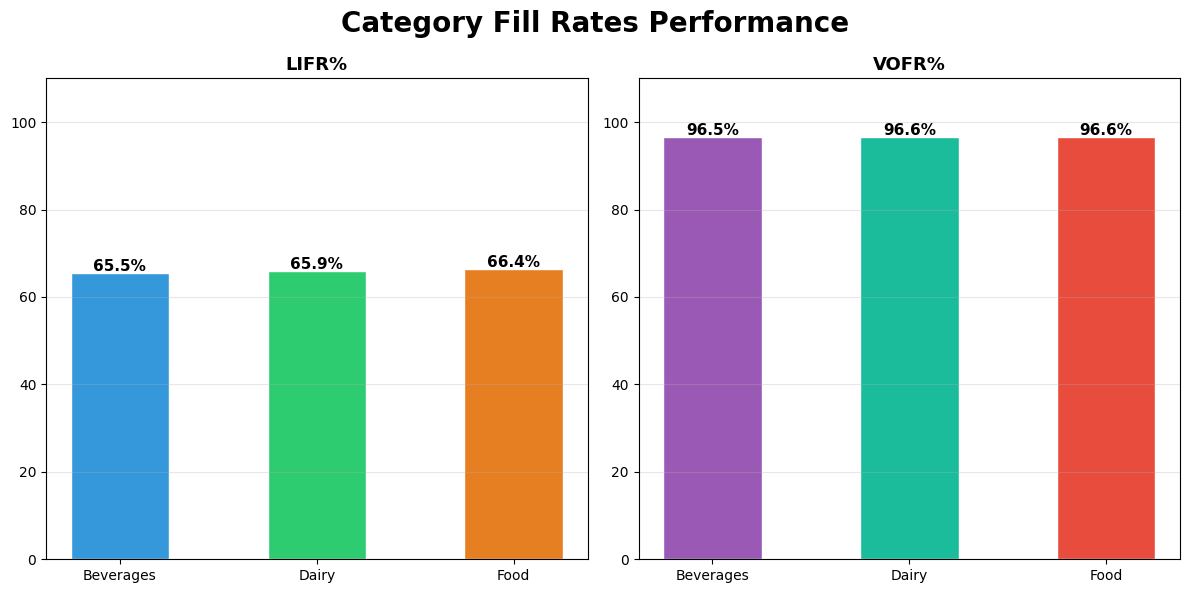

In [27]:
# Compare LIFR% & VOFR% among categories
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for ax, col, title, color_set in zip(
    axes,
    ['LIFR_pct', 'VOFR_pct'],
    ['LIFR%', 'VOFR%'],
    [[COLOR_BLUE, COLOR_GREEN, COLOR_ORANGE],
     [COLOR_PURPLE, COLOR_TEAL, COLOR_RED]]
):
    bars = ax.bar(category_kpis['category'], category_kpis[col],
                  color=color_set, edgecolor='white', width=0.5)

    ax.set_ylim(0, 110)
    ax.set_title(title, fontsize=13, fontweight='bold')

    for bar, val in zip(bars, category_kpis[col]):
        ax.text(bar.get_x() + bar.get_width()/2, val + 0.5,
                f'{val:.1f}%', ha='center', fontsize=11, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)

fig.suptitle(
    'Category Fill Rates Performance',
    fontsize=20, fontweight='bold'
)
plt.tight_layout()
plt.show()

## Region-level Analysis

In [28]:
# Key metrics at region level
city_kpis = (
    fact_aggregate
    .groupby('city')
    .agg(
        total_orders = ('order_id', 'count'),
        ot_orders    = ('on_time', 'sum'),
        if_orders    = ('in_full', 'sum'),
        otif_orders  = ('otif', 'sum'),
    )
    .reset_index()
)
city_kpis['OT_pct']   = city_kpis['ot_orders']   / city_kpis['total_orders'] * 100
city_kpis['IF_pct']   = city_kpis['if_orders']   / city_kpis['total_orders'] * 100
city_kpis['OTIF_pct'] = city_kpis['otif_orders'] / city_kpis['total_orders'] * 100

display(city_kpis.round(2))

,city,total_orders,ot_orders,if_orders,otif_orders,OT_pct,IF_pct,OTIF_pct
0,Ahmedabad,11061,6433,5995,3244,58.16,54.20,29.33
1,Surat,9696,5935,5095,2916,61.21,52.55,30.07
2,Vadodara,10972,6362,5657,3048,57.98,51.56,27.78


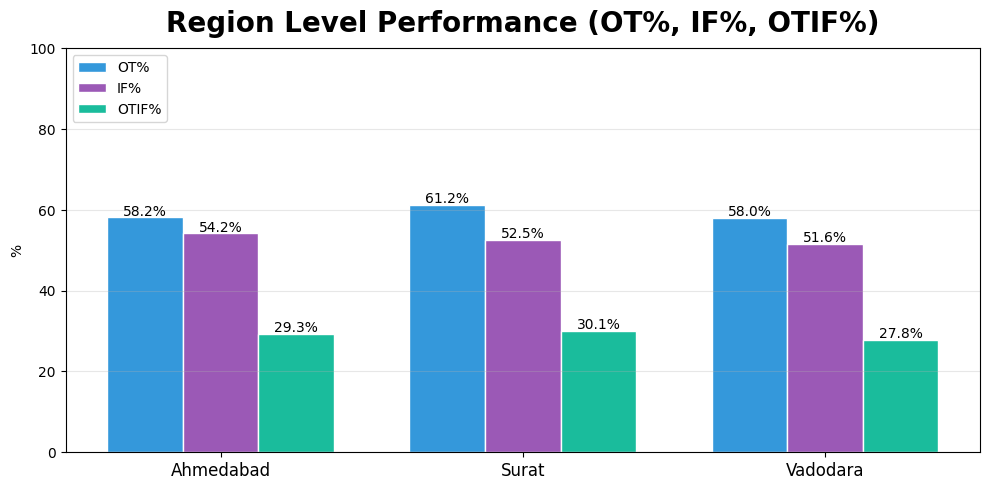

In [29]:
# Grouped bar chart
fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(city_kpis))
w = 0.25

bars_ot = ax.bar(x - w, city_kpis['OT_pct'], width=w, color=COLOR_BLUE, label='OT%', edgecolor='white')
bars_if = ax.bar(x,     city_kpis['IF_pct'], width=w, color=COLOR_PURPLE, label='IF%', edgecolor='white')
bars_otif = ax.bar(x + w, city_kpis['OTIF_pct'], width=w, color=COLOR_TEAL, label='OTIF%', edgecolor='white')

ax.set_xticks(x)
ax.set_xticklabels(city_kpis['city'], fontsize=12)

ax.set_ylabel('%')
ax.set_ylim(0, 100)
ax.set_title('Region Level Performance (OT%, IF%, OTIF%)', fontsize=20, fontweight='bold', y =1.02)

ax.legend(loc='upper left')
ax.grid(axis='y', alpha=0.3)

for bar in bars_ot:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 0.5, f'{yval:.1f}%', ha='center', fontsize=10)

for bar in bars_if:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 0.5, f'{yval:.1f}%', ha='center', fontsize=10)

for bar in bars_otif:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 0.5, f'{yval:.1f}%', ha='center', fontsize=10)

plt.tight_layout()
plt.show()

In [30]:
# Key metrics at region level
city_line_kpis = (
    fact_lines
    .groupby('city')
    .agg(
        total_lines   = ('in_full', 'count'),
        lines_in_full = ('in_full', 'sum'),
        qty_ordered   = ('order_qty', 'sum'),
        qty_delivered = ('delivery_qty', 'sum'),
    )
    .reset_index()
)

city_line_kpis['LIFR_pct'] = city_line_kpis['lines_in_full'] / city_line_kpis['total_lines'] * 100
city_line_kpis['VOFR_pct'] = city_line_kpis['qty_delivered'] / city_line_kpis['qty_ordered'] * 100

display(city_line_kpis.round(2))

,city,total_lines,lines_in_full,qty_ordered,qty_delivered,LIFR_pct,VOFR_pct
0,Ahmedabad,19676,13293,4612298,4462984,67.56,96.76
1,Surat,17842,11898,4190467,4050082,66.69,96.65
2,Vadodara,19578,12470,4624171,4456091,63.69,96.37


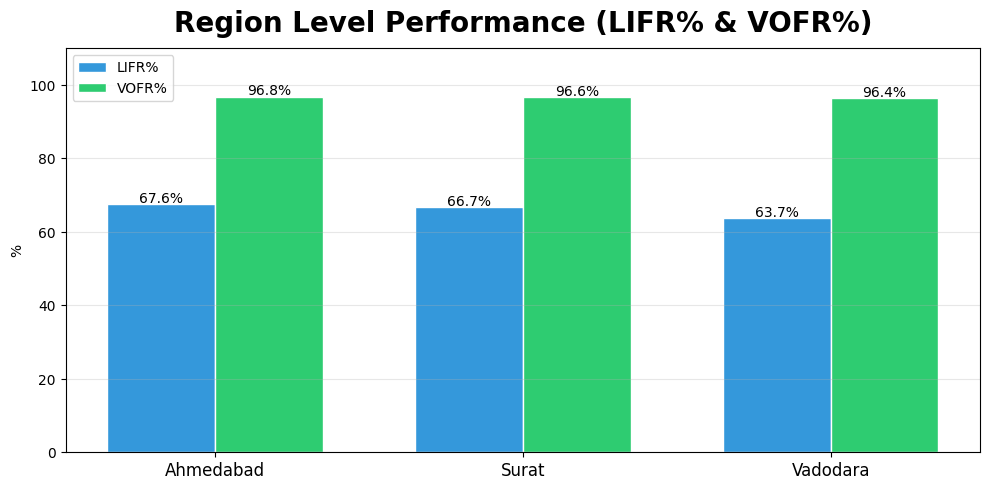

In [31]:
# Grouped bar chart
fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(city_line_kpis))
w = 0.35

bars_lifr = ax.bar(x - w/2, city_line_kpis['LIFR_pct'], width=w, color=COLOR_BLUE, label='LIFR%', edgecolor='white')
bars_vofr = ax.bar(x + w/2, city_line_kpis['VOFR_pct'], width=w, color=COLOR_GREEN, label='VOFR%', edgecolor='white')

ax.set_xticks(x)
ax.set_xticklabels(city_line_kpis['city'], fontsize=12)

ax.set_ylabel('%')
ax.set_ylim(0, 110)
ax.set_title('Region Level Performance (LIFR% & VOFR%)', fontsize=20, fontweight='bold', y =1.02)

ax.legend()
ax.grid(axis='y', alpha=0.3)

for bar in bars_lifr:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 0.5, f'{yval:.1f}%', ha='center', fontsize=10)

for bar in bars_vofr:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 0.5, f'{yval:.1f}%', ha='center', fontsize=10)

plt.tight_layout()
plt.show()

## Delivery Delay Analysis

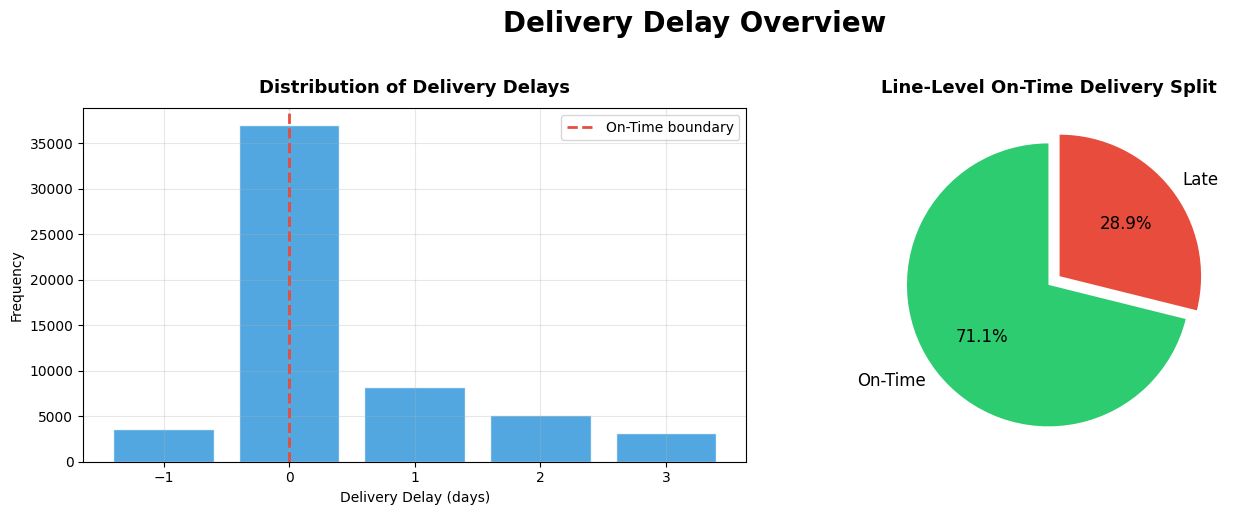

In [32]:
# Overall delay distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Column chart
ax = axes[0]

delay_counts = fact_lines['delivery_delay_days'].value_counts().sort_index()

ax.bar(delay_counts.index, delay_counts.values,
        color=COLOR_BLUE, edgecolor='white', alpha=0.85)

ax.axvline(0, color=COLOR_RED, linewidth=2, linestyle='--', label='On-Time boundary')

ax.set_xlabel('Delivery Delay (days)')
ax.set_ylabel('Frequency')
ax.set_title('Distribution of Delivery Delays', fontsize=13, fontweight='bold', y=1.02)

ax.legend()
ax.grid(alpha=0.3)

# Pie chart: on-time vs late
ax = axes[1]

late   = (fact_lines['delivery_delay_days'] > 0).sum()
ontime = (fact_lines['delivery_delay_days'] <= 0).sum()

ax.pie([ontime, late], labels=['On-Time', 'Late'],
       colors=[COLOR_GREEN, COLOR_RED], autopct='%1.1f%%',
       startangle=90, explode=(0, 0.1), textprops={'fontsize': 12})

ax.set_title('Line-Level On-Time Delivery Split', fontsize=13, fontweight='bold', y=1.02)

fig.suptitle(
    'Delivery Delay Overview',
    fontsize=20, fontweight='bold', y=1.02
)
plt.tight_layout()
plt.show()

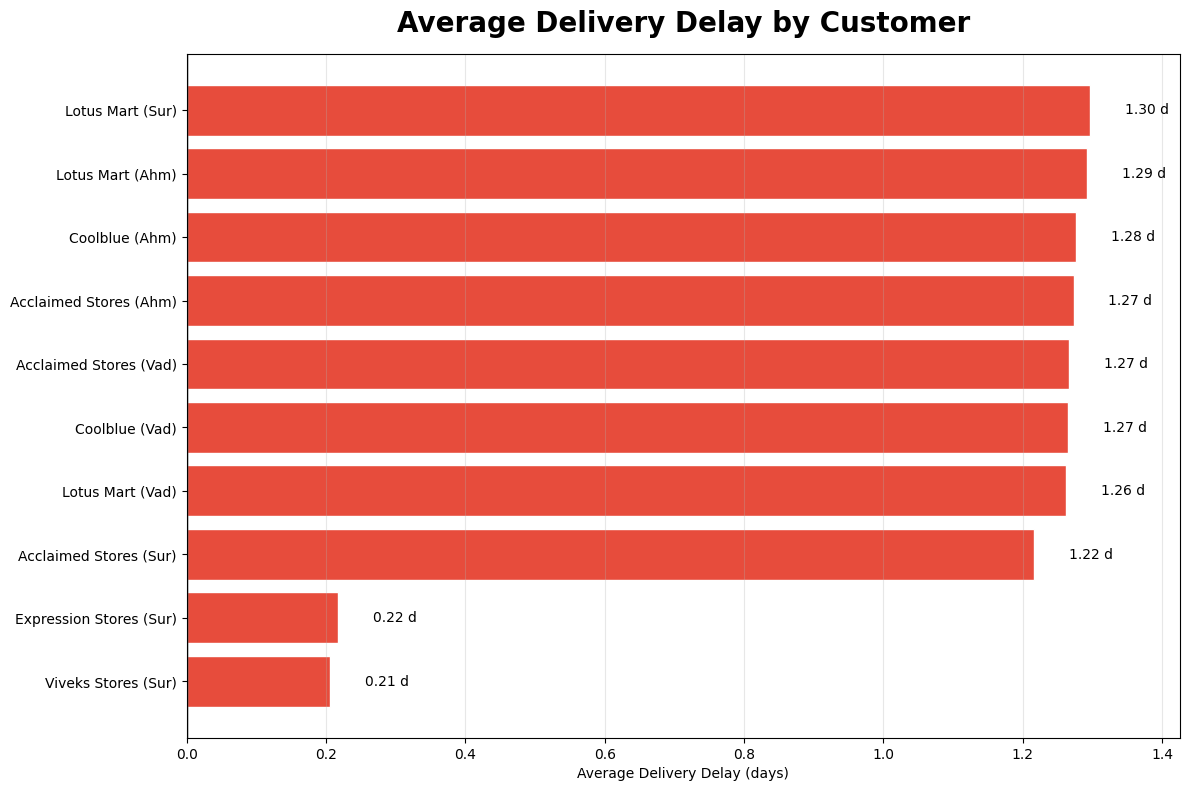

In [33]:
# Average delay by customer (Top 10)
customer_delay = (
    fact_lines
    .groupby(['customer_name', 'city'])[['delivery_delay_days']]
    .agg(avg_delay_days =('delivery_delay_days', 'mean'))
    .sort_values('avg_delay_days', ascending=False)
    .reset_index()
    .head(10)
)

customer_delay_label = customer_delay['customer_name'] + " (" + customer_delay['city'].str[:3] + ")"

fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(customer_delay_label, customer_delay['avg_delay_days'],
               color=[COLOR_RED if v > 0 else COLOR_GREEN for v in customer_delay['avg_delay_days']],
               edgecolor='white')

ax.axvline(0, color='black', linewidth=1)

ax.set_xlabel('Average Delivery Delay (days)')
ax.set_title('Average Delivery Delay by Customer', fontsize=20, fontweight='bold', y=1.02)

for bar, val in zip(bars, customer_delay['avg_delay_days']):
    ax.text(val + (0.05 if val >= 0 else -0.05),
            bar.get_y() + bar.get_height()/2,
            f'{val:.2f} d', va='center',
            ha='left' if val >= 0 else 'right', fontsize=10)

ax.invert_yaxis()
ax.margins(x=0.10)
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

## Advanced / Additional Metrics

Total Quantity Shortfall : 457,779 units
Shortfall Rate           : 3.41%



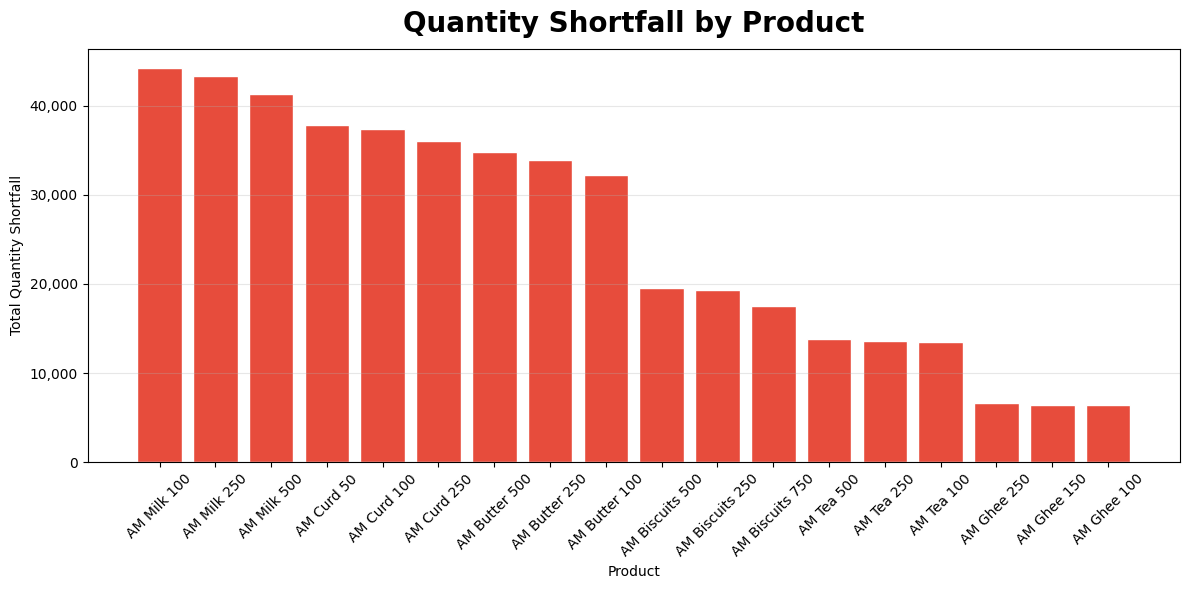

In [34]:
# Unmet Demand (shortfall in quantity)
fact_lines['qty_shortfall'] = fact_lines['order_qty'] - fact_lines['delivery_qty']
fact_lines['shortfall_pct'] = fact_lines['qty_shortfall'] / fact_lines['order_qty'] * 100

total_shortfall   = fact_lines['qty_shortfall'].sum()
shortfall_rate    = total_shortfall / fact_lines['order_qty'].sum() * 100

print(f'Total Quantity Shortfall : {total_shortfall:,.0f} units')
print(f'Shortfall Rate           : {shortfall_rate:.2f}%')
print()

# Shortfall by product
product_shortfall = (
    fact_lines.groupby('product_name')['qty_shortfall']
    .agg('sum')
    .sort_values(ascending=False)
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(product_shortfall['product_name'], product_shortfall['qty_shortfall'],
       color=COLOR_RED, edgecolor='white')

ax.set_xlabel('Product')
ax.set_ylabel('Total Quantity Shortfall')
ax.set_title('Quantity Shortfall by Product', fontsize=20, fontweight='bold', y=1.02)

ax.tick_params(axis='x', rotation=45)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

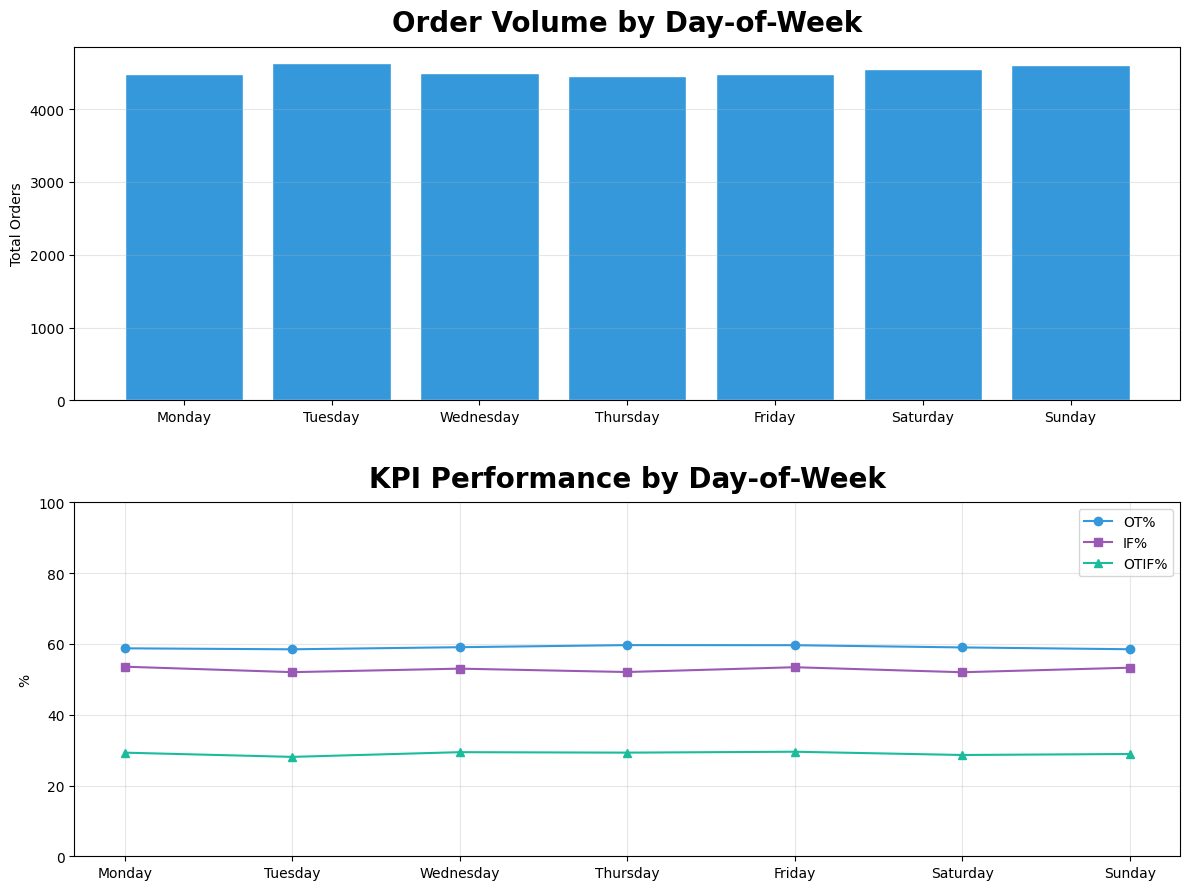

In [35]:
# Day-of-Week ordering pattern
dow_kpis = (
    fact_aggregate
    .groupby('day_of_week')
    .agg(
        total_orders = ('order_id', 'count'),
        ot_pct       = ('on_time',  'mean'),
        if_pct       = ('in_full',  'mean'),
        otif_pct     = ('otif',     'mean'),
    )
    .reset_index()
)
dow_kpis[['ot_pct','if_pct','otif_pct']] *= 100

day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
dow_kpis['day_of_week'] = pd.Categorical(dow_kpis['day_of_week'],
                                          categories=day_order, ordered=True)
dow_kpis = dow_kpis.sort_values('day_of_week')

fig, axes = plt.subplots(2, 1, figsize=(12, 9))

axes[0].bar(dow_kpis['day_of_week'], dow_kpis['total_orders'],
            color=COLOR_BLUE, edgecolor='white')

axes[0].set_ylabel('Total Orders')
axes[0].set_title('Order Volume by Day-of-Week', fontsize=20, fontweight='bold', y=1.02)
axes[0].grid(axis='y', alpha=0.3)


axes[1].plot(dow_kpis['day_of_week'], dow_kpis['ot_pct'], marker='o', label='OT%', color=COLOR_BLUE)
axes[1].plot(dow_kpis['day_of_week'], dow_kpis['if_pct'], marker='s', label='IF%', color=COLOR_PURPLE)
axes[1].plot(dow_kpis['day_of_week'], dow_kpis['otif_pct'], marker='^', label='OTIF%', color=COLOR_TEAL)

axes[1].set_ylabel('%')
axes[1].set_ylim(0, 100)
axes[1].set_title('KPI Performance by Day-of-Week', fontsize=20, fontweight='bold', y=1.02)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout(h_pad=3.0)
plt.show()

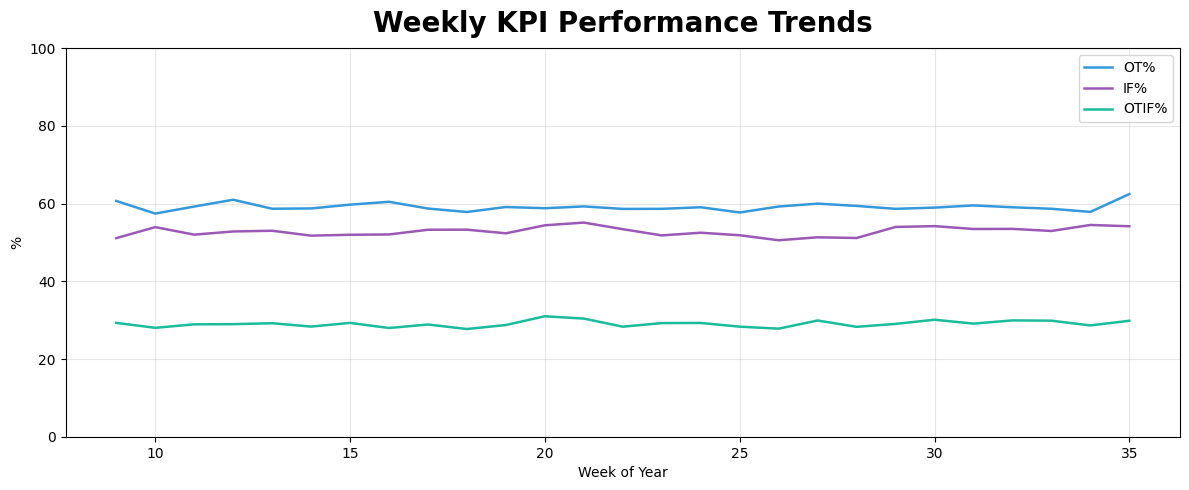

In [36]:
# Weekly KPI trend
weekly_kpis = (
    fact_aggregate
    .groupby('week_of_year')
    .agg(
        total_orders = ('order_id', 'count'),
        ot_pct       = ('on_time',  'mean'),
        if_pct       = ('in_full',  'mean'),
        otif_pct     = ('otif',     'mean'),
    )
    .reset_index()
)
weekly_kpis[['ot_pct','if_pct','otif_pct']] *= 100

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(weekly_kpis['week_of_year'], weekly_kpis['ot_pct'], label='OT%', color=COLOR_BLUE, linewidth=1.8)
ax.plot(weekly_kpis['week_of_year'], weekly_kpis['if_pct'], label='IF%', color=COLOR_PURPLE, linewidth=1.8)
ax.plot(weekly_kpis['week_of_year'], weekly_kpis['otif_pct'], label='OTIF%', color=COLOR_TEAL, linewidth=1.8)

ax.set_xlabel('Week of Year')
ax.set_ylabel('%')
ax.set_ylim(0, 100)
ax.set_title('Weekly KPI Performance Trends', fontsize=20, fontweight='bold', y=1.02)

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [37]:
# Scatter plot: OT% vs IF%
fig = px.scatter(
    customer_kpis,
    x='OT_pct', y='IF_pct',
    size='total_orders', color='city',
    hover_name='customer_name',
    size_max=40,
    template='plotly_white',
    width=900, height=600,
    labels={
        'OT_pct': 'OT%',
        'IF_pct': 'IF%'
    }
)

fig.add_hline(y=IF_pct,  line_dash='dash', line_color='gray',
              annotation_text='Overall IF avg', annotation_position='bottom right')
fig.add_vline(x=OT_pct,  line_dash='dash', line_color='gray',
              annotation_text='Overall OT avg', annotation_position='top right')

fig.update_layout(
    title={
        'text': '<b>OT% vs IF% by Customer</b>',
        'x': 0.5,
        'font': dict(size=20)
    }
)

fig.show()

## Key Insights & Recommendations

In [38]:
# Customers KPI (Sorted by OTIF% gap)
customer_kpis_sorted = customer_kpis.sort_values(by='OTIF_gap', ascending=True)
bottom_3_cust = customer_kpis_sorted.head(3)[['customer_name', 'city', 'OTIF_gap']].values.tolist()
top_3_cust = customer_kpis_sorted.tail(3)[::-1][['customer_name', 'city', 'OTIF_gap']].values.tolist()

# Products KPI (Sorted by LIFR%)
product_kpis_sorted = product_kpis.sort_values(by='LIFR_pct', ascending=True)
bottom_3_prod = product_kpis_sorted.head(3)[['product_name', 'LIFR_pct']].values.tolist()
top_3_prod = product_kpis_sorted.tail(3)[::-1][['product_name', 'LIFR_pct']].values.tolist()

# Customer with highest average delay
top_3_delay_cust = customer_delay.head(3)[['customer_name', 'city', 'avg_delay_days']].values.tolist()

# City with lowest OTIF%
worst_city_otif = city_kpis.loc[city_kpis['OTIF_pct'].idxmin(), 'city']

In [39]:
# Analysis report
print(f"""
================================================================================
  SUPPLY CHAIN PERFORMANCE ANALYSIS: KEY INSIGHTS & STRATEGIC RECOMMENDATIONS
================================================================================

1. EXECUTIVE SUMMARY
--------------------------------------------------------------------------------
This report evaluates AtliQ Mart’s core supply chain execution capabilities across
its active operational regions (Surat, Ahmedabad, and Vadodara). The objective is
to diagnose recurring service fulfillment issues that are currently jeopardizing
key customer annual contract renewals. Addressing these performance gaps is
identified as a strategic prerequisite prior to executing any Tier-1 metro expansions.


2. AGGREGATE SERVICE LEVEL METRICS vs. SLA TARGETS
--------------------------------------------------------------------------------
Performance assessment indicates systemic deviations from established baseline targets:

* On-Time Delivery (OT%):       {OT_pct:.2f}%  | Target: {avg_ot_target:.2f}%  | Gap: {OT_pct - avg_ot_target:+5.2f}%
* In-Full Delivery (IF%):       {IF_pct:.2f}%  | Target: {avg_if_target:.2f}%  | Gap: {IF_pct - avg_if_target:+5.2f}%
* On-Time In-Full (OTIF%):      {OTIF_pct:.2f}%  | Target: {avg_otif_target:.2f}%  | Gap: {OTIF_pct - avg_otif_target:+5.2f}%

Supporting Operational Metrics:
* Line Fill Rate (LIFR%):       {LIFR:.2f}%
* Volume Fill Rate (VOFR%):     {VOFR:.2f}%


3. CRITICAL OPERATIONAL FINDINGS
--------------------------------------------------------------------------------
3.1 Comprehensive Target Shortfalls
All three core supply chain KPIs fail to meet contractual targets. The critical
On-Time In-Full (OTIF%) service level trails target parameters by {abs(OTIF_pct - avg_otif_target):.2f}%,
indicating that simultaneous order completeness and timing alignment represents a
statistical anomaly rather than a baseline standard.

3.2 Supply vs. Logistics Bottleneck Diagnosis
In-Full performance ({IF_pct:.2f}%) demonstrates a wider deficit than On-Time logistics
performance ({OT_pct:.2f}%). This variance suggests that downstream fulfillment
failures are primarily driven by upstream constraints, such as inaccurate demand
forecasting, production bottlenecks, or inventory stockouts, rather than localized
transit delays.

3.3 Customer Risk Assessment (OTIF% - Target OTIF%)
A concentrated subset of high-volume customer accounts is bearing the brunt of
these service disruptions, establishing a clear link to contract non-renewal risks.

* Top 3 Highest Churn-Risk Accounts (Highest OTIF% Gap):
  1. {bottom_3_cust[0][0]} - {bottom_3_cust[0][1]} ({bottom_3_cust[0][2]:.2f}%)
  2. {bottom_3_cust[1][0]} - {bottom_3_cust[1][1]} ({bottom_3_cust[1][2]:.2f}%)
  3. {bottom_3_cust[2][0]} - {bottom_3_cust[2][1]} ({bottom_3_cust[2][2]:.2f}%)

* Top 3 Benchmark Accounts (Lowest OTIF% Gap):
  1. {top_3_cust[0][0]} - {top_3_cust[0][1]} ({top_3_cust[0][2]:.2f}%)
  2. {top_3_cust[1][0]} - {top_3_cust[1][1]} ({top_3_cust[1][2]:.2f}%)
  3. {top_3_cust[2][0]} - {top_3_cust[2][1]} ({top_3_cust[2][2]:.2f}%)

3.4 SKU Inventory Availability (LIFR% Distribution)
Line Fill Rate variations isolate specific inventory segments requiring immediate
replenishment adjustments.

* Most Critical SKU Deficits (Lowest LIFR%):
  - 1. '{bottom_3_prod[0][0]}' ({bottom_3_prod[0][1]:.2f}%)
  - 2. '{bottom_3_prod[1][0]}' ({bottom_3_prod[1][1]:.2f}%)
  - 3. '{bottom_3_prod[2][0]}' ({bottom_3_prod[2][1]:.2f}%)

* Optimal Availability SKUs (Highest LIFR%):
  - 1. '{top_3_prod[0][0]}' ({top_3_prod[0][1]:.2f}%)
  - 2. '{top_3_prod[1][0]}' ({top_3_prod[1][1]:.2f}%)
  - 3. '{top_3_prod[2][0]}' ({top_3_prod[2][1]:.2f}%)

3.5 Regional Performance Variance
Geographic evaluation shows that the {worst_city_otif.upper()} regional hub possesses
the lowest aggregate OTIF% performance within the network, signaling infrastructure
or localized carrier optimization weaknesses.

3.6 Transit Delay Profile
At an order-line level, {(fact_lines['delivery_delay_days'] > 0).mean() * 100:.1f}% of all deliveries register
as delayed. Long-tail turnaround times are heavily concentrated within specific
strategic accounts:
  1. {top_3_delay_cust[0][0]} - {top_3_delay_cust[0][1]} (Average Delay: {top_3_delay_cust[0][2]:.2f} days)
  2. {top_3_delay_cust[1][0]} - {top_3_delay_cust[1][1]} (Average Delay: {top_3_delay_cust[1][2]:.2f} days)
  3. {top_3_delay_cust[2][0]} - {top_3_delay_cust[2][1]} (Average Delay: {top_3_delay_cust[2][2]:.2f} days)


4. STRATEGIC RECOMMENDATIONS
--------------------------------------------------------------------------------
1. Demand Forecast Optimization: Restructure safety stock buffers and demand
   planning cycles specifically for underperforming SKUs ('{bottom_3_prod[0][0]}',
   '{bottom_3_prod[1][0]}', '{bottom_3_prod[2][0]}') to reverse the In-Full deficit.

2. Immediate Account Intervention: Deploy a customer success task force to initiate
   service-recovery protocols for the lowest-performing accounts ('{bottom_3_cust[0][0]} - {bottom_3_cust[0][1]}',
   '{bottom_3_cust[1][0]} - {bottom_3_cust[1][1]}', '{bottom_3_cust[2][0]} - {bottom_3_cust[2][1]}') to protect contract renewals.

3. Regional Network Audit: Commission a root-cause investigation into the
   {worst_city_otif.upper()} regional warehouse configuration, fulfillment
   workflows, and regional last-mile fleet dependencies.

4. Performance Cadence Realignment: Upgrade reporting visibility from monthly retrospective
   reviews to a weekly dynamic OTIF dashboard to accelerate operational adjustments.

5. Cross-Functional Diagnostics: Implement an end-to-end tracking framework to cleanly
   demarcate time losses attributable to manufacturing delays versus third party logistic
   carrier transit bottlenecks.
================================================================================
""")



  SUPPLY CHAIN PERFORMANCE ANALYSIS: KEY INSIGHTS & STRATEGIC RECOMMENDATIONS

1. EXECUTIVE SUMMARY
--------------------------------------------------------------------------------
This report evaluates AtliQ Mart’s core supply chain execution capabilities across
its active operational regions (Surat, Ahmedabad, and Vadodara). The objective is
to diagnose recurring service fulfillment issues that are currently jeopardizing
key customer annual contract renewals. Addressing these performance gaps is
identified as a strategic prerequisite prior to executing any Tier-1 metro expansions.


2. AGGREGATE SERVICE LEVEL METRICS vs. SLA TARGETS
--------------------------------------------------------------------------------
Performance assessment indicates systemic deviations from established baseline targets:

* On-Time Delivery (OT%):       59.03%  | Target: 85.24%  | Gap: -26.21%
* In-Full Delivery (IF%):       52.78%  | Target: 76.31%  | Gap: -23.53%
* On-Time In-Full (OTIF%):      29.02%  